# 06_05 Nonparametric Tests: Ranks, Permutations and the KS Test

**Learning objectives**
- Explain why **ranks** make a test robust to outliers and skewness, and carry out the **Mann-Whitney U** (Wilcoxon rank-sum) test by hand.
- Run **permutation tests** for any statistic (a difference of means, of medians, a correlation) and understand why they are exact.
- Use the **sign test** and the **Wilcoxon signed-rank test** for paired data and the **Kolmogorov-Smirnov (KS)** test for whole distributions.
- Compare **power**: when the $t$-test wins, when a rank test wins, and what the **relative efficiency** says.

**Prerequisites:** [06_03 Hypothesis testing](06_03_hypothesis_testing_core.ipynb), [06_04 The common tests](06_04_common_tests.ipynb), [05_04 The bootstrap and Monte Carlo](../../module_05_sampling/notebooks/05_04_bootstrap_monte_carlo.ipynb), [05_07 Order statistics](../../module_05_sampling/notebooks/05_07_order_statistics_extremes.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, itertools

## 2. Prerequisite recap

- A **hypothesis test** compares a statistic with its null distribution (06_03). The $t$ and ANOVA tests of 06_04 rely on (nearly) Normal means and are sensitive to outliers.
- The **empirical CDF** $\hat F_n(x)=\frac1n\#\{x_i\le x\}$ estimates the CDF and converges to it (05_04, 05_07).
- **Ranks** are the positions of the observations in the sorted pooled sample; ties get the average rank.
- **Exchangeability:** if two groups come from the same distribution, every labelling of the pooled data is equally likely.

## 3. Intuition and story

The $t$-test uses the *values*; one huge outlier in one group inflates its mean **and** its variance, which can hide a real difference. Nonparametric tests ask a gentler question that does not depend on the shape of the data:

- **Rank tests** replace each value by its rank (1 = smallest) and test whether one group's ranks are systematically higher. A value of 30 hours and a value of 10 hours get consecutive ranks: the *size* of the outlier is forgotten.
- **Permutation tests** keep the original statistic (say the difference of means) but get its null distribution by **shuffling the group labels** many times: if the labels do not matter, the observed difference should look like a typical shuffled one. No distribution is assumed.
- **KS tests** compare entire distributions (the maximum gap between two CDFs), not just a mean.

The price is a little power when the data really are Normal (about 5 %); the reward is validity and often *more* power for skewed or heavy-tailed data.

## 4. Formal definitions

| Test | Hypothesis | Statistic | Null distribution |
|---|---|---|---|
| **Mann-Whitney U** (Wilcoxon rank-sum) | the two samples come from the same distribution (versus one tends to be larger) | $U_1=R_1-\frac{n_1(n_1+1)}2$, $R_1$ = rank sum of group 1 | exact (all rank arrangements), or Normal with mean $\frac{n_1n_2}2$ and variance $\frac{n_1n_2(n_1+n_2+1)}{12}$ |
| **Sign test** | median difference is 0 | number of positive differences | Binomial$(n,\frac12)$ |
| **Wilcoxon signed-rank** | symmetric differences centred at 0 | sum of ranks of $|d_i|$ with positive $d_i$ | exact or Normal |
| **Permutation test** | exchangeability of labels | any statistic $T$ | recompute $T$ over all (or many random) relabellings; $p=\frac{\#\{|T^*|\ge|T_{obs}|\}}{\#\text{relabellings}}$ |
| **KS one-sample** | data come from a specified CDF $F_0$ | $D=\sup_x|\hat F_n(x)-F_0(x)|$ | Kolmogorov distribution |
| **KS two-sample** | two samples have the same CDF | $D=\sup_x|\hat F_{n_1}(x)-\hat F_{n_2}(x)|$ | Kolmogorov distribution |

**Effect size for Mann-Whitney:** $\hat\theta=U_1/(n_1n_2)=\widehat{P}(X_1>X_2)$ (the "probability of superiority" or AUC); 0.5 means no difference. For two Normals with the same SD, $\theta=\Phi(d/\sqrt2)$.

**Asymptotic relative efficiency** of the Wilcoxon test against the $t$-test: $0.955$ for Normal data, $1.0$ for uniform, and **above 1** (up to $\infty$) for heavy-tailed data (Laplace: 1.5).

## 5. Derivations

### 5.1 The mean and variance of the rank sum under $H_0$
If the groups are identical, the $n_1$ ranks of group 1 are a random subset of $\{1,\dots,N\}$ ($N=n_1+n_2$) chosen without replacement. Each rank has mean $\frac{N+1}2$, so $E[R_1]=\frac{n_1(N+1)}2$ and hence $E[U_1]=\frac{n_1n_2}2$. Using the variance of a sample drawn without replacement (the finite population correction, 01_04), $\mathrm{Var}(R_1)=\frac{n_1n_2(N+1)}{12}$. **In plain words.** Under $H_0$ the rank sum is just the sum of a random handful of the numbers $1,\dots,N$, whose mean and spread we can write down.

### 5.2 $U/(n_1n_2)$ is the probability of superiority
$U_1$ counts the pairs $(x,y)$ with $x>y$ (plus half the ties), so $U_1/(n_1n_2)$ estimates $P(X>Y)$. **In plain words.** Pick one observation from each group at random: the Mann-Whitney statistic estimates how often group 1 wins. It is the area under the ROC curve (Module 10) of a classifier that uses the value as its score.

### 5.3 Why a permutation test is exact
Under $H_0$ the labels are exchangeable, so the observed value of $T$ is one of $\binom{N}{n_1}$ equally likely values obtained by relabelling. The p-value is the share of relabellings with a statistic at least as extreme; including the observed labelling guarantees $P(p\le\alpha)\le\alpha$ for every $\alpha$. With many relabellings one samples them: the Monte Carlo p-value is $(1+\#\text{extreme})/(1+B)$. **In plain words.** The data themselves, shuffled, show what "no effect" looks like.

### 5.4 The KS statistic and the probability integral transform
If the data really come from the continuous $F_0$ then $F_0(X_i)$ are Uniform(0,1), so the null distribution of $D$ does **not depend on $F_0$** (distribution-free); $\sqrt nD$ converges to the Kolmogorov distribution (about 1.36 at the 95 % level). **In plain words.** Whatever the continuous distribution, the largest vertical gap between the sample CDF and the true CDF fluctuates by about $1.36/\sqrt n$. If parameters are *estimated* from the same data the test is too conservative (use the Lilliefors correction or simulation).

### 5.5 Why ranks resist outliers
Replacing $x$ by its rank bounds the influence of any single observation: the largest value contributes the rank $N$ whether it is 12 or 12 million. The mean has an unbounded influence. **In plain words.** A rank test counts *who beats whom*, not by how much.

## 6. Properties and relationships

- **What each test detects:** Mann-Whitney detects a shift in location or stochastic dominance; it is *not* a test of equal medians unless the shapes are the same. A permutation test detects exactly the difference in the chosen statistic.
- **Assumptions:** independence is still required; ties need a correction; the KS test is for continuous data and is less powerful than the $t$-test for pure location shifts but sensitive to differences in shape.
- **Link to confidence intervals:** the Hodges-Lehmann estimator (median of all pairwise differences) and bootstrap/permutation intervals give a confidence interval for the shift (05_04).
- **Power:** with Normal data the Mann-Whitney test needs about 5 % more observations than the $t$-test; with outliers or heavy tails it can need far fewer (Section 9.2).
- **Link to ML and AI:** the Mann-Whitney statistic *is* the AUC of a score; permutation tests are the standard way to test a model's importance score or to compare two models without assuming a distribution; the KS distance is used to detect **data drift** and to check calibration of predicted probabilities.

## 7. 2D visuals

### 7.1 From values to ranks
Ticket-resolution times of two processes (hours). The huge value 30.2 hours is only **one rank** above 9.9, so it barely changes a rank test but distorts the means and variances: the left plot shows the values, the right plot the ranks.

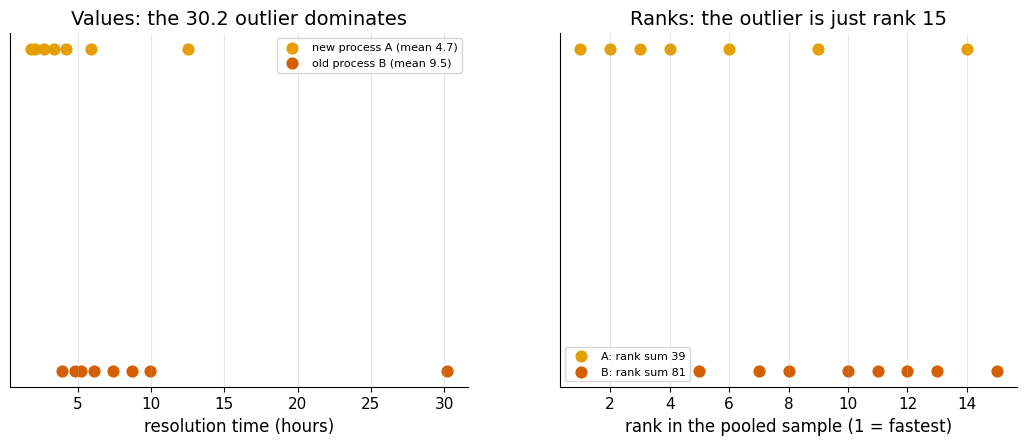

ranks of A: [ 2  4  1  9  3  6 14] (sum 39) | ranks of B: [ 7 10  5 12  8 13 11 15] (sum 81) | total 120 = 15 x 16 / 2


In [2]:
A = np.array([2.1, 3.4, 1.8, 5.9, 2.7, 4.2, 12.5]); B = np.array([4.8, 6.1, 3.9, 8.7, 5.2, 9.9, 7.4, 30.2])
pooled = np.concatenate([A, B]); ranks = stats.rankdata(pooled); rA, rB = ranks[:7], ranks[7:]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].scatter(A, np.zeros(7) + 0.1, s=60, color=SIM, label=f"new process A (mean {A.mean():.1f})"); axes[0].scatter(B, np.zeros(8) - 0.1, s=60, color=HIGHLIGHT, label=f"old process B (mean {B.mean():.1f})")
axes[0].set_yticks([]); axes[0].set_xlabel("resolution time (hours)"); axes[0].set_title("Values: the 30.2 outlier dominates"); axes[0].legend(fontsize=8)
axes[1].scatter(rA, np.zeros(7) + 0.1, s=60, color=SIM, label=f"A: rank sum {rA.sum():.0f}"); axes[1].scatter(rB, np.zeros(8) - 0.1, s=60, color=HIGHLIGHT, label=f"B: rank sum {rB.sum():.0f}")
axes[1].set_yticks([]); axes[1].set_xlabel("rank in the pooled sample (1 = fastest)"); axes[1].set_title("Ranks: the outlier is just rank 15"); axes[1].legend(fontsize=8)
plt.show()
print(f"ranks of A: {rA.astype(int)} (sum {rA.sum():.0f}) | ranks of B: {rB.astype(int)} (sum {rB.sum():.0f}) | total {ranks.sum():.0f} = 15 x 16 / 2")
assert rA.sum() == 39 and rB.sum() == 81 and ranks.sum() == 120

### 7.2 The null distribution of the rank-sum statistic
All $\binom{15}7=6435$ ways to split the ranks 1 to 15 into a group of 7 and a group of 8 give the exact null distribution of $U$; it is already close to the Normal curve with mean 28 and SD 8.64. The observed $U_A=11$ falls in the left tail.

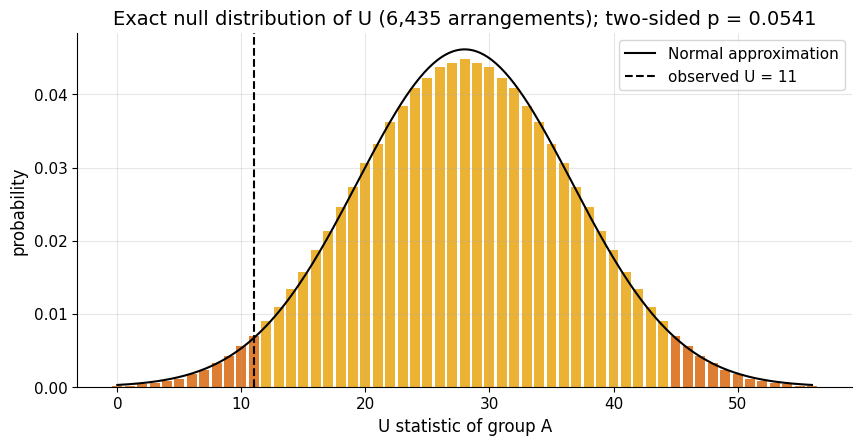

number of arrangements 6435 | exact two-sided p-value 0.0541 | null mean 28.00, SD 8.641 (theory 28 and 8.641)


In [3]:
n1, n2 = 7, 8
Us = np.array([sum(c) - n1 * (n1 + 1) / 2 for c in itertools.combinations(range(1, n1 + n2 + 1), n1)])
vals, cnts = np.unique(Us, return_counts=True); u_obs = rA.sum() - n1 * (n1 + 1) / 2
p_exact = np.mean((Us <= u_obs) | (Us >= n1 * n2 - u_obs))
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(vals, cnts / cnts.sum(), color=[HIGHLIGHT if (v <= u_obs or v >= n1 * n2 - u_obs) else SIM for v in vals], alpha=0.8)
xs = np.linspace(0, 56, 300); ax.plot(xs, stats.norm.pdf(xs, 28, np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)), color="black", label="Normal approximation"); ax.axvline(u_obs, color="black", linestyle="--", label=f"observed U = {u_obs:.0f}")
ax.set_xlabel("U statistic of group A"); ax.set_ylabel("probability"); ax.set_title(f"Exact null distribution of U (6,435 arrangements); two-sided p = {p_exact:.4f}"); ax.legend()
plt.show()
print(f"number of arrangements {len(Us)} | exact two-sided p-value {p_exact:.4f} | null mean {Us.mean():.2f}, SD {Us.std():.3f} (theory 28 and {np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12):.3f})")
assert len(Us) == 6435 and abs(Us.mean() - 28) < 1e-9 and abs(Us.std() - np.sqrt(7 * 8 * 16 / 12)) < 1e-9

### 7.3 A permutation distribution
Shuffle the 15 group labels 20,000 times and recompute the difference of means each time: the histogram is the null distribution of the statistic; the observed difference ($-4.87$ hours) is in the left tail.

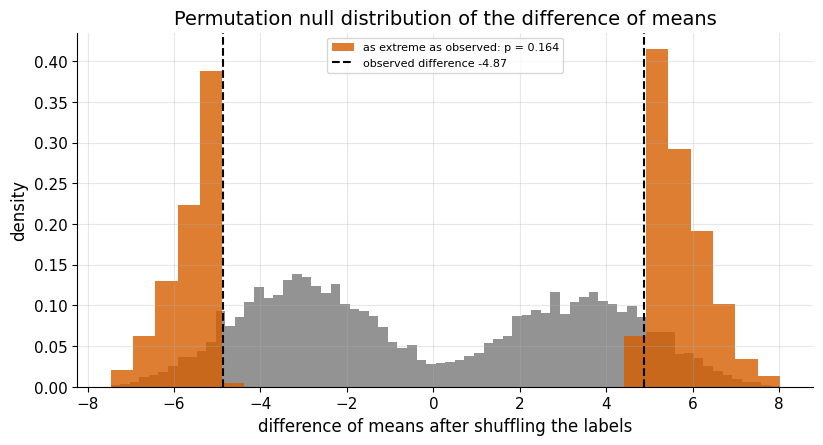

permutation p-value 0.1643 | Welch t-test p = 0.1774 | Mann-Whitney p = 0.0541


In [4]:
obs_diff = A.mean() - B.mean(); perm_rng = np.random.default_rng(1)
diffs = np.array([ (lambda p: p[:7].mean() - p[7:].mean())(perm_rng.permutation(pooled)) for _ in range(20_000)])
p_perm = (1 + np.sum(np.abs(diffs) >= abs(obs_diff))) / (1 + diffs.size)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.hist(diffs, bins=70, density=True, color=NEUTRAL, alpha=0.7); ax.hist(diffs[np.abs(diffs) >= abs(obs_diff)], bins=30, density=True, color=HIGHLIGHT, alpha=0.8, label=f"as extreme as observed: p = {p_perm:.3f}")
ax.axvline(obs_diff, color="black", linestyle="--", label=f"observed difference {obs_diff:.2f}"); ax.axvline(-obs_diff, color="black", linestyle="--"); ax.set_xlabel("difference of means after shuffling the labels"); ax.set_ylabel("density"); ax.set_title("Permutation null distribution of the difference of means"); ax.legend(fontsize=8)
plt.show()
print(f"permutation p-value {p_perm:.4f} | Welch t-test p = {stats.ttest_ind(A, B, equal_var=False).pvalue:.4f} | Mann-Whitney p = {stats.mannwhitneyu(A, B).pvalue:.4f}")
assert abs(p_perm - 0.164) < 0.01

### 7.4 The KS statistic: the largest gap between two CDFs
The empirical CDFs of the two ticket samples and the maximum vertical gap $D$ (marked): the KS test judges whether such a gap could arise if both samples came from the same distribution.

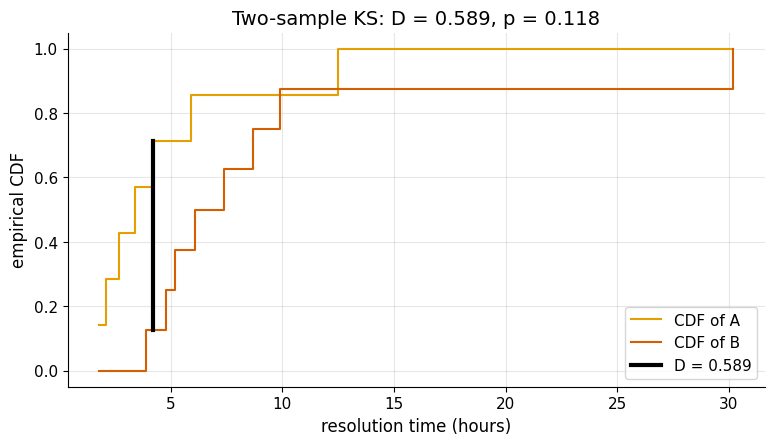

In [5]:
xs = np.sort(pooled); FA = np.searchsorted(np.sort(A), xs, side="right") / len(A); FB = np.searchsorted(np.sort(B), xs, side="right") / len(B)
k = np.argmax(np.abs(FA - FB)); ks = stats.ks_2samp(A, B)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.step(xs, FA, where="post", color=SIM, label="CDF of A"); ax.step(xs, FB, where="post", color=HIGHLIGHT, label="CDF of B"); ax.plot([xs[k], xs[k]], [FA[k], FB[k]], color="black", linewidth=3, label=f"D = {abs(FA[k] - FB[k]):.3f}")
ax.set_xlabel("resolution time (hours)"); ax.set_ylabel("empirical CDF"); ax.set_title(f"Two-sample KS: D = {ks.statistic:.3f}, p = {ks.pvalue:.3f}"); ax.legend()
plt.show()
assert abs(ks.statistic - abs(FA[k] - FB[k])) < 1e-12

## 8. 3D visuals

### 8.1 Static: power of the Mann-Whitney test over (probability of superiority, group size)
With the effect measured as $\theta=P(X_2>X_1)$ and the Normal approximation of $U$, the power of the two-sided test ($\alpha=0.05$) rises from the floor $0.05$ at $\theta=0.5$ to 1 as $\theta$ and $n$ grow. The surface lets us read the sample size for a target $\theta$: for $\theta=0.64$ (a medium effect, $d=0.5$) about 70 per group give 80 % power (the $t$-test needs 64, 06_04).

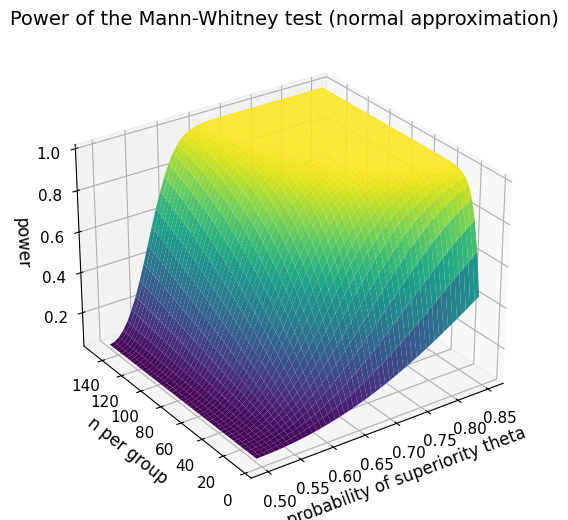

theta for d = 0.5: 0.638 | n per group for 80 % power at that theta: 70


In [6]:
th_ax = np.linspace(0.5, 0.85, 50); n_ax = np.arange(5, 151, 3)
def power_mw(theta, n):
    se0 = np.sqrt((2 * n + 1) / (12 * n * n)); se1 = se0 * 1.0               # simple version: the same SE under H1
    return stats.norm.sf(1.96 - (theta - 0.5) / se1) + stats.norm.cdf(-1.96 - (theta - 0.5) / se1)
PWm = np.array([[power_mw(t_, n_) for t_ in th_ax] for n_ in n_ax]); Tg, Ng = np.meshgrid(th_ax, n_ax)
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Tg, Ng, PWm, cmap="viridis", edgecolor="none")
ax.set_xlabel("probability of superiority theta"); ax.set_ylabel("n per group"); ax.set_zlabel("power"); ax.set_title("Power of the Mann-Whitney test (normal approximation)"); ax.view_init(elev=28, azim=-125)
plt.show()
theta_d05 = stats.norm.cdf(0.5 / np.sqrt(2)); print(f"theta for d = 0.5: {theta_d05:.3f} | n per group for 80 % power at that theta: {next(n_ for n_ in range(3, 400) if power_mw(theta_d05, n_) >= 0.8)}")
assert abs(power_mw(0.5, 30) - 0.05) < 1e-4

### 8.2 Interactive Plotly version of 8.1
Hover to read the power.

In [7]:
fig = go.Figure(go.Surface(x=th_ax, y=n_ax, z=PWm, colorscale="Viridis"))
fig.update_layout(title="Power of the Mann-Whitney test", width=760, height=560, scene=dict(xaxis_title="theta = P(X2 > X1)", yaxis_title="n per group", zaxis_title="power"))
fig.show()

### 8.3 Static: how the KS statistic fluctuates
The distribution of $\sqrt nD$ for samples from a known distribution does not depend on $n$ or on the distribution: simulate 4,000 values for several $n$ and compare with the Kolmogorov law (a surface of the CDF over $n$ would be flat in $n$).

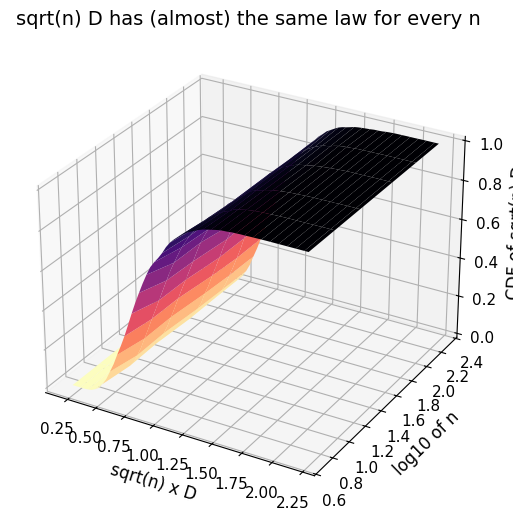

95th percentile of sqrt(n) D by n: {10: 1.308, 50: 1.31, 200: 1.332} | Kolmogorov limit 1.358


In [8]:
ns_k = [5, 10, 20, 50, 100, 200]; grid = np.linspace(0.2, 2.2, 60); surf = []
for n_ in ns_k:
    d = np.array([stats.kstest(rng.normal(size=n_), "norm").statistic for _ in range(3000)]) * np.sqrt(n_)
    surf.append([np.mean(d <= g) for g in grid])
Gg, Ng2 = np.meshgrid(grid, np.log10(ns_k))
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Gg, Ng2, np.array(surf), cmap="magma_r", edgecolor="none")
ax.set_xlabel("sqrt(n) x D"); ax.set_ylabel("log10 of n"); ax.set_zlabel("CDF of sqrt(n) D"); ax.set_title("sqrt(n) D has (almost) the same law for every n"); ax.view_init(elev=28, azim=-60)
plt.show()
print("95th percentile of sqrt(n) D by n:", {n_: round(float(np.percentile(np.array([stats.kstest(rng.normal(size=n_), 'norm').statistic for _ in range(3000)]) * np.sqrt(n_), 95)), 3) for n_ in (10, 50, 200)}, "| Kolmogorov limit 1.358")

## 9. Simulation vs theory

### 9.1 Type I error with skewed data
Two samples of 15 from the same heavy-tailed (lognormal) distribution: the Welch $t$, Mann-Whitney and permutation tests (on the means) are compared on their false-positive rates. None exceeds 5 %; the Welch test is conservative here (about 2.4 %), which costs it power.

In [9]:
reps = 3000; gen = np.random.default_rng(9)
rej = {"Welch t": 0, "Mann-Whitney": 0, "permutation (means)": 0}
for _ in range(reps):
    x, y = gen.lognormal(0, 1.2, 15), gen.lognormal(0, 1.2, 15)
    rej["Welch t"] += stats.ttest_ind(x, y, equal_var=False).pvalue < 0.05; rej["Mann-Whitney"] += stats.mannwhitneyu(x, y).pvalue < 0.05
    rej["permutation (means)"] += stats.permutation_test((x, y), lambda a, b: a.mean() - b.mean(), n_resamples=299, random_state=int(gen.integers(1e9))).pvalue < 0.05
print({k: round(v / reps, 4) for k, v in rej.items()})
assert all(0.015 < v / reps < 0.075 for v in rej.values()) and rej['Welch t'] < rej['Mann-Whitney']

{'Welch t': np.float64(0.024), 'Mann-Whitney': np.float64(0.0427), 'permutation (means)': np.float64(0.0453)}


### 9.2 Power: Normal data versus heavy-tailed data
The same shift (0.8 SD) in two settings: Normal data, where the $t$-test is best, and Student-$t_2$ data with very heavy tails, where the rank test wins by a wide margin.

In [10]:
def power_pair(draw, shift, n=25, reps=4000):
    a = draw((reps, n)); b = draw((reps, n)) + shift
    return (np.mean(stats.ttest_ind(a, b, axis=1).pvalue < 0.05), np.mean([stats.mannwhitneyu(x_, y_).pvalue < 0.05 for x_, y_ in zip(a[:1500], b[:1500])]))
pn = power_pair(lambda s: rng.normal(size=s), 0.8); pt = power_pair(lambda s: rng.standard_t(2, size=s), 1.5)
print(pd.DataFrame({"Normal data, shift 0.8": pn, "Student t2 data, shift 1.5": pt}, index=["t-test", "Mann-Whitney"]).round(3).to_string())
assert pn[0] > pn[1] - 0.01 and pt[1] > pt[0] + 0.1

              Normal data, shift 0.8  Student t2 data, shift 1.5
t-test                         0.791                       0.657
Mann-Whitney                   0.769                       0.924


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("Mann-Whitney U: stats.mannwhitneyu(A, B, alternative='two-sided') ->", stats.mannwhitneyu(A, B), "| exact:", stats.mannwhitneyu(A, B, method='exact').pvalue.round(4))
print("Wilcoxon signed-rank (paired): stats.wilcoxon(x, y) ->", stats.wilcoxon([3.1, 2.8, 4.0, 3.5, 2.9, 3.7, 4.2], [2.7, 2.9, 3.4, 3.0, 2.8, 3.1, 3.6]))
print("sign test: stats.binomtest(k_positive, n, 0.5) ->", round(stats.binomtest(6, 7, 0.5).pvalue, 4))
print("permutation test: stats.permutation_test((A, B), lambda a, b: a.mean() - b.mean(), n_resamples=9999) ->", round(stats.permutation_test((A, B), lambda a, b: a.mean() - b.mean(), n_resamples=9999, random_state=1).pvalue, 4))
print("KS two-sample: stats.ks_2samp(A, B) ->", stats.ks_2samp(A, B), "| one-sample: stats.kstest(x, 'expon', args=(0, scale))")
print("ranks: stats.rankdata(pooled) ->", stats.rankdata([3, 1, 2, 2]), "(ties get the average rank)")
print("Kruskal-Wallis (three or more groups, the rank version of ANOVA): stats.kruskal(g1, g2, g3).pvalue ->", round(stats.kruskal([1, 2, 3, 4], [3, 4, 5, 6], [6, 7, 8, 9]).pvalue, 4))
print("probability of superiority: U / (n1 n2) =", round(stats.mannwhitneyu(B, A).statistic / (len(A) * len(B)), 4))

Mann-Whitney U: stats.mannwhitneyu(A, B, alternative='two-sided') -> MannwhitneyuResult(statistic=np.float64(11.0), pvalue=np.float64(0.054079254079254076)) | exact: 0.0541
Wilcoxon signed-rank (paired): stats.wilcoxon(x, y) -> WilcoxonResult(statistic=np.float64(1.5), pvalue=np.float64(0.046875))
sign test: stats.binomtest(k_positive, n, 0.5) -> 0.125
permutation test: stats.permutation_test((A, B), lambda a, b: a.mean() - b.mean(), n_resamples=9999) -> 0.1427
KS two-sample: stats.ks_2samp(A, B) -> KstestResult(statistic=np.float64(0.5892857142857143), pvalue=np.float64(0.11810411810411808), statistic_location=np.float64(4.2), statistic_sign=np.int8(1)) | one-sample: stats.kstest(x, 'expon', args=(0, scale))
ranks: stats.rankdata(pooled) -> [4.  1.  2.5 2.5] (ties get the average rank)
Kruskal-Wallis (three or more groups, the rank version of ANOVA): stats.kruskal(g1, g2, g3).pvalue -> 0.0141
probability of superiority: U / (n1 n2) = 0.8036


## 11. Real-world worked examples

---
### Example 1 (main): did the new ticket process speed up resolution?

**Scenario.** Resolution times (hours) of support tickets: **new process A** (7 tickets): 2.1, 3.4, 1.8, 5.9, 2.7, 4.2, 12.5. **Old process B** (8 tickets): 4.8, 6.1, 3.9, 8.7, 5.2, 9.9, 7.4, 30.2. Is the new process faster? (two-sided, $\alpha=0.05$)

**Questions**
1. Compute the **ranks**, the rank sums and the **Mann-Whitney $U$** by hand, and the exact p-value.
2. Compare with the **Welch $t$-test** and a **permutation test of the means**. Why do they disagree?
3. What is the **probability of superiority** $P(A<B)$?
4. Check by simulation the Type I error and power of the three tests for data like these.

### 11.1 By hand
**Q1.** Pooled sorted values with their groups: 1.8 A (1), 2.1 A (2), 2.7 A (3), 3.4 A (4), 3.9 B (5), 4.2 A (6), 4.8 B (7), 5.2 B (8), 5.9 A (9), 6.1 B (10), 7.4 B (11), 8.7 B (12), 9.9 B (13), 12.5 A (14), 30.2 B (15). Rank sums: $R_A=1+2+3+4+6+9+14=39$, $R_B=81$ (total $120=15\times16/2$ ✓). $U_A=R_A-\frac{7\times8}2=39-28=\mathbf{11}$ and $U_B=56-11=45$. Under $H_0$: mean $28$, SD $=\sqrt{7\cdot8\cdot16/12}=8.64$, so $z=(11-28)/8.64=-1.97$ (normal approximation $p\approx0.049$); the **exact two-sided p-value is 0.054**.

**Q2.** Welch: $\bar x_A=4.66$, $\bar x_B=9.53$, but the outlier 30.2 inflates group B's variance: $t=-1.45$, **p = 0.177**. A permutation test of the difference of means (all 6,435 relabellings, absolute difference) gives **p = 0.164**, also not significant (scipy's doubled-tail convention gives 0.143). The two mean-based tests are damaged by the single outlier.

**Q3.** $\hat P(A>B)=U_A/56=0.196$, so $P(A<B)=\mathbf{0.80}$: a random ticket under the new process is faster than a random ticket under the old one 80 % of the time.

In [12]:
res_mw = stats.mannwhitneyu(A, B, alternative="two-sided", method="exact"); res_t = stats.ttest_ind(A, B, equal_var=False)
res_perm = stats.permutation_test((A, B), lambda a, b: a.mean() - b.mean(), n_resamples=20_000, random_state=1)      # scipy enumerates all 6,435 splits; its two-sided p is twice the smaller tail
d_all = np.array([pooled[list(sel)].mean() - np.delete(pooled, list(sel)).mean() for sel in itertools.combinations(range(15), 7)])
p_perm_exact = np.mean(np.abs(d_all) >= abs(A.mean() - B.mean()) - 1e-9)                                              # share of splits at least as extreme in absolute value
u_a = res_mw.statistic; theta = 1 - u_a / (len(A) * len(B))
print(f"Q1: U_A = {u_a:.0f}, exact p = {res_mw.pvalue:.4f}; normal approximation z = {(u_a - 28) / np.sqrt(7 * 8 * 16 / 12):.2f}, p = {2 * stats.norm.cdf((u_a - 28) / np.sqrt(7 * 8 * 16 / 12)):.4f}")
print(f"Q2: Welch t = {res_t.statistic:.2f}, p = {res_t.pvalue:.4f} | permutation p = {p_perm_exact:.4f} (absolute-value definition, all 6,435 splits; scipy's doubled-tail version {res_perm.pvalue:.4f}) | without the outlier 30.2: Welch p = {stats.ttest_ind(A, B[:-1], equal_var=False).pvalue:.4f}, Mann-Whitney p = {stats.mannwhitneyu(A, B[:-1]).pvalue:.4f}")
print(f"Q3: P(A < B) = {theta:.3f}")

Q1: U_A = 11, exact p = 0.0541; normal approximation z = -1.97, p = 0.0491
Q2: Welch t = -1.45, p = 0.1774 | permutation p = 0.1646 (absolute-value definition, all 6,435 splits; scipy's doubled-tail version 0.1427) | without the outlier 30.2: Welch p = 0.2692, Mann-Whitney p = 0.0973
Q3: P(A < B) = 0.804


### 11.2 In code with `scipy`, and the asserts

In [13]:
assert u_a == 11 and abs(res_mw.pvalue - 0.0541) < 5e-4 and abs(res_t.pvalue - 0.1774) < 5e-4 and abs(p_perm_exact - 0.1637) < 0.003 and abs(res_perm.pvalue - 0.1427) < 0.003 and abs(theta - 0.8036) < 1e-3
assert abs(p_exact - res_mw.pvalue) < 1e-9                                  # the enumeration of 7.2 reproduces scipy's exact p-value
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Generate data like these (lognormal times, the new process 40 % faster, an occasional outlier) and compare the three tests: Type I error when the processes are identical, and power when the new one is faster.

In [14]:
sg = np.random.default_rng(31); reps = 2500
def draw_tickets(n, scale):
    x = sg.lognormal(np.log(4.5 * scale), 0.6, n); x[sg.random(n) < 0.06] *= 4; return x
rows = []
for label, scale_a in [("identical processes (Type I error)", 1.0), ("new process 40 % faster (power)", 0.6)]:
    hits = np.zeros(3)
    for _ in range(reps):
        a, b = draw_tickets(7, scale_a), draw_tickets(8, 1.0)
        hits += [stats.ttest_ind(a, b, equal_var=False).pvalue < 0.05, stats.mannwhitneyu(a, b).pvalue < 0.05, stats.permutation_test((a, b), lambda u, v: u.mean() - v.mean(), n_resamples=199, random_state=int(sg.integers(1e9))).pvalue < 0.05]
    rows.append(dict(zip(["Welch t", "Mann-Whitney", "permutation (means)"], hits / reps), setting=label))
sim_tab = pd.DataFrame(rows).set_index("setting"); print(sim_tab.round(3).to_string())
assert all(sim_tab.iloc[0] < 0.08) and sim_tab.iloc[1]["Mann-Whitney"] > sim_tab.iloc[1]["Welch t"]

                                    Welch t  Mann-Whitney  permutation (means)
setting                                                                       
identical processes (Type I error)    0.027         0.043                0.034
new process 40 % faster (power)       0.170         0.241                0.218


### 11.4 Plots with the regions shaded

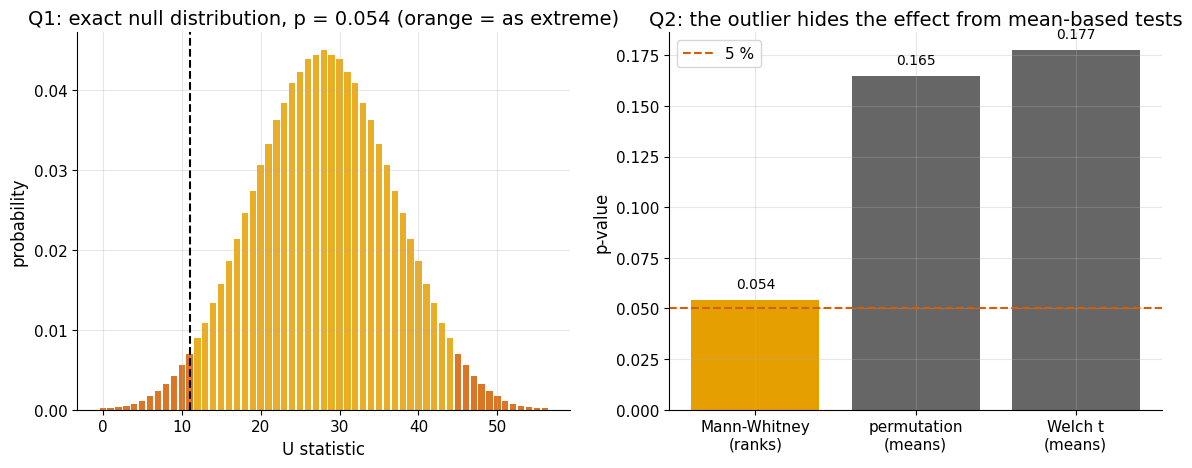

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
axes[0].bar(vals, cnts / cnts.sum(), color=[HIGHLIGHT if (v <= u_obs or v >= 56 - u_obs) else SIM for v in vals], alpha=0.85); axes[0].axvline(u_obs, color="black", linestyle="--"); axes[0].set_xlabel("U statistic"); axes[0].set_ylabel("probability"); axes[0].set_title(f"Q1: exact null distribution, p = {res_mw.pvalue:.3f} (orange = as extreme)")
labels = ["Mann-Whitney\n(ranks)", "permutation\n(means)", "Welch t\n(means)"]; pv = [res_mw.pvalue, p_perm_exact, res_t.pvalue]
axes[1].bar(labels, pv, color=[SIM, NEUTRAL, NEUTRAL]); axes[1].axhline(0.05, color=HIGHLIGHT, linestyle="--", label="5 %")
for i_, v_ in enumerate(pv): axes[1].text(i_, v_ + 0.006, f"{v_:.3f}", ha="center")
axes[1].set_ylabel("p-value"); axes[1].set_title("Q2: the outlier hides the effect from mean-based tests"); axes[1].legend()
plt.show()

### 11.5 Interpretation and decision (Example 1)
- The rank test says the new process is **probably faster but not conclusively so**: $U=11$, exact **p = 0.054** (just above 5 %). A randomly chosen ticket under the new process is faster than a randomly chosen old-process ticket **80 %** of the time.
- The mean-based tests are much less convinced: **Welch p = 0.177** and the permutation test of the means **p = 0.164**, because the single 30.2-hour ticket makes the old process's mean and variance enormous, which hides the fact that *almost every* new-process ticket is faster. Remove that one ticket and Mann-Whitney moves to p = 0.097 while Welch moves to 0.27: the rank test uses the *ordering* and is hardly affected by one extreme value.
- In simulated data of this kind (small samples, occasional outliers) all three tests keep their level (Type I error 2.7 % for Welch, 4.3 % for Mann-Whitney, 3.4 % for the permutation test) and the rank test has the best power (24 % against 17 % for Welch), although power is low for only 7 and 8 tickets.
- **Decision.** Report "new process faster in 80 % of paired comparisons, p = 0.054", not "no difference": the sample is too small for a firm conclusion. Collect 20 or more tickets per process before deciding, and report the effect as a probability of superiority and a shift, not as a difference of means.

---
### Example 2: an exact permutation test with six users per group

**Scenario.** Time spent per session (minutes) for two versions of an app with only **6 users each**: version X: 18, 22, 19, 25, 30, 21; version Y: 24, 29, 33, 27, 35, 31. We test whether the means differ.

**Questions**
1. List all $\binom{12}6=924$ relabellings and compute the **exact permutation p-value** of the difference of means.
2. Compare with the Welch $t$-test and the Mann-Whitney test.
3. How large is the difference, and what interval does a bootstrap give?

### 11.6 By hand
**Q1.** The observed difference of means is $\bar y-\bar x=29.83-22.5=7.33$ minutes. We count how many of the 924 ways to split the 12 values into two groups of 6 give a difference at least as large in absolute value; the answer is computed below (**$p=0.0216$**: 20 of the 924 splits).

**Q2.** The Welch $t$ is 3.01 with $p=0.013$; the Mann-Whitney $p$ is **0.0260** (exact), the smallest attainable p-value being $2/924=0.0022$.

**Q3.** A bootstrap interval for the difference is computed below.

observed difference 7.33 | relabellings 924, as extreme 20, exact p = 0.0216 | Welch p = 0.0133 | Mann-Whitney exact p = 0.0260
bootstrap 95 % interval for the difference: (2.83, 11.50)


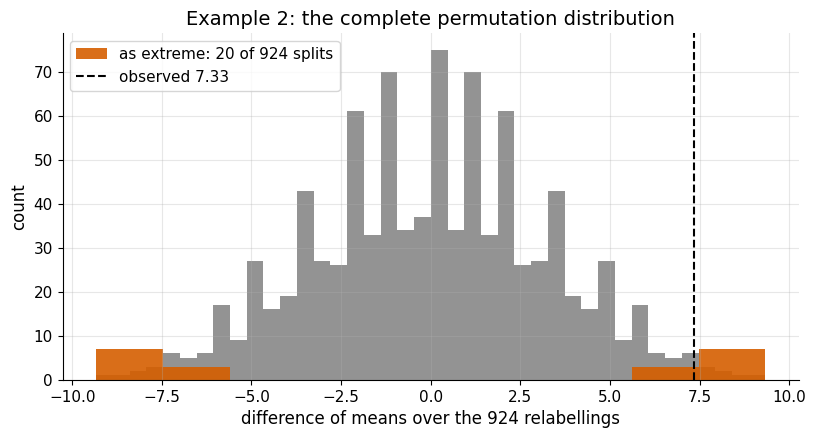

In [16]:
X = np.array([18, 22, 19, 25, 30, 21]); Y = np.array([24, 29, 33, 27, 35, 31]); pool2 = np.concatenate([X, Y])
obs2 = Y.mean() - X.mean()
extreme = 0; total = 0
for idx in itertools.combinations(range(12), 6):
    mask = np.zeros(12, bool); mask[list(idx)] = True
    d_ = pool2[~mask].mean() - pool2[mask].mean(); total += 1; extreme += abs(d_) >= abs(obs2) - 1e-9
p_exact2 = extreme / total
w2 = stats.ttest_ind(Y, X, equal_var=False); m2 = stats.mannwhitneyu(Y, X, method="exact")
bs = stats.bootstrap((Y, X), lambda y, x: y.mean() - x.mean(), n_resamples=9999, random_state=1, method="percentile")
print(f"observed difference {obs2:.2f} | relabellings {total}, as extreme {extreme}, exact p = {p_exact2:.4f} | Welch p = {w2.pvalue:.4f} | Mann-Whitney exact p = {m2.pvalue:.4f}")
print(f"bootstrap 95 % interval for the difference: ({bs.confidence_interval.low:.2f}, {bs.confidence_interval.high:.2f})")
assert total == 924 and extreme == 20 and abs(w2.pvalue - 0.0133) < 5e-4 and abs(m2.pvalue - 0.0260) < 5e-4
fig, ax = plt.subplots(figsize=(9.5, 4.5))
dd = []
for idx in itertools.combinations(range(12), 6):
    mk = np.zeros(12, bool); mk[list(idx)] = True; dd.append(pool2[~mk].mean() - pool2[mk].mean())
dd = np.array(dd); ax.hist(dd, bins=40, color=NEUTRAL, alpha=0.7); ax.hist(dd[np.abs(dd) >= abs(obs2) - 1e-9], bins=10, color=HIGHLIGHT, alpha=0.9, label=f"as extreme: {extreme} of {total} splits")
ax.axvline(obs2, color="black", linestyle="--", label=f"observed {obs2:.2f}"); ax.set_xlabel("difference of means over the 924 relabellings"); ax.set_ylabel("count"); ax.set_title("Example 2: the complete permutation distribution"); ax.legend()
plt.show()

### 11.7 Interpretation and decision (Example 2)
- The exact permutation test over all 924 relabellings gives **p = 0.0216**: only 20 of the 924 splits produce a difference of means as large as the observed **7.3 minutes**. Welch ($p=0.013$) and Mann-Whitney ($p=0.026$) agree that version Y keeps users longer.
- The bootstrap 95 % interval for the difference is **2.8 to 11.5 minutes**: significantly positive but imprecise with six users per group.
- A permutation test is **exact for any sample size** and any statistic: no Normal approximation was needed, and the smallest p-value achievable with 12 observations is $2/924=0.0022$.
- **Decision.** Version Y appears better, but with 6 users per group treat it as a promising lead; confirm with at least 30 users per version and report the interval, not only the p-value.

---
### Example 3: is the latency Exponential? (the KS test and the Lilliefors problem)

**Scenario.** **60 response times** (ms) are suspected to be Exponential. Test with the one-sample KS test; also test whether the **before and after** samples of a configuration change have the same distribution (two-sample KS).

**Questions**
1. Compute $D$ and the p-value when the Exponential mean is *known* (50 ms) and when it is *estimated* from the data.
2. Why is the second p-value misleading, and what is a correct p-value (simulation)?
3. Detect a change of shape with the two-sample KS test.

### 11.8 By hand
**Q1.** $D=\max_i\max\{|i/n-F_0(x_{(i)})|,\ |(i-1)/n-F_0(x_{(i)})|\}$; the 95 % critical value is about $1.36/\sqrt{60}=0.176$. The test with the *known* mean is exact; with the mean *estimated* the sample CDF is pulled towards the fitted CDF, so $D$ is smaller than under a fixed $F_0$ and the standard p-value is **too large** (the test is conservative).

**Q2.** The correct reference is obtained by simulating samples from the fitted Exponential, re-estimating the mean each time and recording $D$ (the Lilliefors test).

**Q3.** The two-sample KS test compares the empirical CDFs of the before and after samples directly.

known mean 50: D = 0.0995, p = 0.5584 | estimated mean: D = 0.1157, naive p = 0.3694, Lilliefors p (simulated) = 0.1655
95th percentile of D with estimated mean: 0.1383 (fixed-F0 critical value 0.1753)
two-sample KS: D = 0.300, p = 0.0014 | t-test on the means: p = 0.504


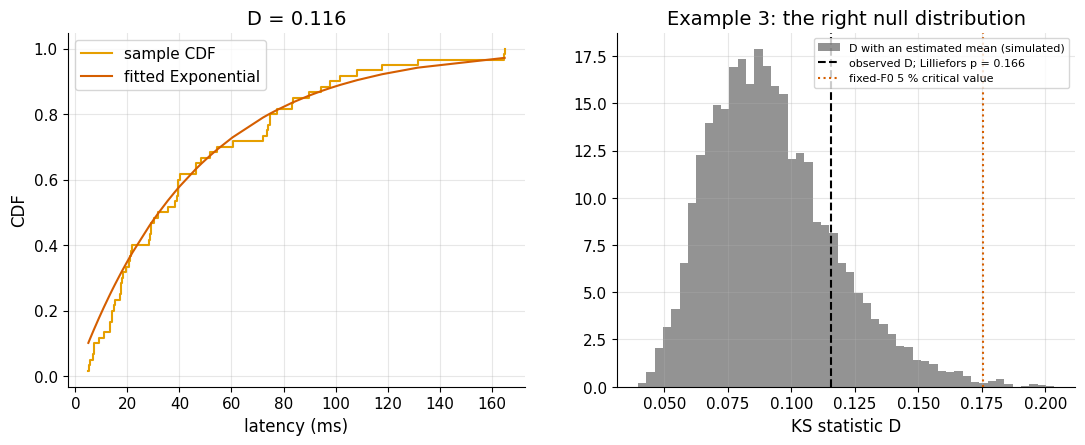

In [17]:
lat = np.random.default_rng(4).gamma(1.6, 50 / 1.6, 60)                           # truly Gamma (shape 1.6), mean 50 ms: not Exponential
D_known = stats.kstest(lat, "expon", args=(0, 50)); D_est = stats.kstest(lat, "expon", args=(0, lat.mean()))
sim_D = np.array([stats.kstest(s, "expon", args=(0, s.mean())).statistic for s in np.random.default_rng(5).exponential(lat.mean(), (6000, 60))])
p_lillie = np.mean(sim_D >= D_est.statistic)
print(f"known mean 50: D = {D_known.statistic:.4f}, p = {D_known.pvalue:.4f} | estimated mean: D = {D_est.statistic:.4f}, naive p = {D_est.pvalue:.4f}, Lilliefors p (simulated) = {p_lillie:.4f}")
print(f"95th percentile of D with estimated mean: {np.percentile(sim_D, 95):.4f} (fixed-F0 critical value {1.358 / np.sqrt(60):.4f})")
before = np.random.default_rng(6).exponential(50, 80); after = np.random.default_rng(7).gamma(4, 12.5, 80)
ks2 = stats.ks_2samp(before, after); print(f"two-sample KS: D = {ks2.statistic:.3f}, p = {ks2.pvalue:.4f} | t-test on the means: p = {stats.ttest_ind(before, after, equal_var=False).pvalue:.3f}")
assert np.percentile(sim_D, 95) < 1.358 / np.sqrt(60) - 0.02 and p_lillie < D_est.pvalue and ks2.pvalue < 0.05
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
xs = np.sort(lat); axes[0].step(xs, np.arange(1, 61) / 60, where="post", color=SIM, label="sample CDF"); axes[0].plot(xs, stats.expon(scale=lat.mean()).cdf(xs), color=HIGHLIGHT, label="fitted Exponential"); axes[0].set_xlabel("latency (ms)"); axes[0].set_ylabel("CDF"); axes[0].set_title(f"D = {D_est.statistic:.3f}"); axes[0].legend()
axes[1].hist(sim_D, bins=50, density=True, color=NEUTRAL, alpha=0.7, label="D with an estimated mean (simulated)"); axes[1].axvline(D_est.statistic, color="black", linestyle="--", label=f"observed D; Lilliefors p = {p_lillie:.3f}"); axes[1].axvline(1.358 / np.sqrt(60), color=HIGHLIGHT, linestyle=":", label="fixed-F0 5 % critical value"); axes[1].set_xlabel("KS statistic D"); axes[1].set_title("Example 3: the right null distribution"); axes[1].legend(fontsize=8)
plt.show()

### 11.9 Interpretation and decision (Example 3)
- The latency data are truly Gamma-distributed (shape 1.6), not Exponential, but the **one-sample KS test cannot tell**: D = 0.116 gives a naive p of 0.37; the correct (Lilliefors) p is **0.17** because the mean was estimated from the same data. The naive p-value is more than twice the correct one (the 95 % critical value of $D$ with an estimated mean is 0.138, not 0.175). Even correctly, 60 observations are too few to reject.
- For the **before and after** samples (the same mean, 50 ms, but a different shape) the two-sample KS test finds the difference clearly (**D = 0.30, p = 0.0014**), while the $t$-test on the means says nothing (p = 0.50): a change that keeps the mean but moves the shape (here the removal of very short and very long times) is invisible to mean-based tests.
- **Decision.** Use KS tests to compare distributions (before/after, train/production), but do not take a non-significant one-sample KS as proof of a distribution family; judge fit by Q-Q plots (05_07) and by what matters for the use (tail probabilities). When parameters are estimated, always use the Lilliefors-type correction.

## 12. Where it is used

### Statistics
- **Small, skewed or ordinal data** (ratings, times, counts with outliers): Mann-Whitney, Wilcoxon, Kruskal-Wallis; **exact tests** when approximations fail (Fisher, permutation); goodness-of-fit and two-sample comparison of distributions (KS, Anderson-Darling).
- **Robust estimation:** Hodges-Lehmann shift estimates and rank-based regression.

### Data science
- **A/B tests on heavy-tailed metrics** (revenue, session length, time to resolution): rank or permutation tests alongside bootstrap intervals (06_07); checking whether a metric's distribution changed after a release.
- **Data drift detection:** the two-sample KS test (one feature at a time) between training and production data; with hundreds of features a multiple-testing correction is essential (06_06).

### ML and AI
- **The Mann-Whitney $U$ is the AUC** of a score; testing whether one model's scores rank positives above negatives better than another's is a (paired) rank problem (Module 10).
- **Permutation importance** and permutation tests for model significance; KS-based calibration and distribution-shift checks; non-parametric comparison of models across many datasets (Wilcoxon signed-rank, Friedman).

## 13. Common pitfalls and misconceptions

- **"Nonparametric means no assumptions":** independence is still required, ties need care, and the rank tests answer a question about *stochastic dominance*, not about medians (unless shapes are the same).
- **Mann-Whitney is not a test of equal medians:** two distributions with equal medians but different shapes can give a small p-value.
- **Less power for Normal data:** the loss is small (about 5 %) but real; with small samples the exact p-value can only take few values (smallest $2/924$ in Example 2).
- **Estimated parameters break the KS test:** use Lilliefors/simulation (Example 3). The KS test is also weak in the tails; the Anderson-Darling test is more sensitive there.
- **Permutation tests need exchangeability:** paired or clustered data must be permuted within pairs or clusters, not freely.
- **Too many permutations is fine, too few is not:** with $B$ random relabellings the p-value has Monte Carlo error $\sqrt{p(1-p)/B}$ (05_04); report at least 4 decimals only if $B$ is large.
- **Large samples:** with very large $n$ every test finds tiny differences; report the effect size (probability of superiority, the shift) and an interval.
- **KS with discrete data** is conservative; use a chi-square test instead.

## 14. Exercises

1. Group 1: 12, 15, 11, 18, 14; Group 2: 20, 17, 25, 22, 19, 24. Compute the rank sums, $U$ and the exact p-value with `scipy`; also the probability of superiority.
2. Eight users rated two versions of an interface on a scale 1 to 10 (same users): v1: 6, 7, 5, 8, 6, 7, 9, 5; v2: 8, 7, 7, 9, 8, 8, 9, 7. Apply the sign test and the Wilcoxon signed-rank test (handle the zero differences as `scipy` does).
3. Show by simulation that a single outlier of size 100 added to a sample of 20 Normal observations destroys the power of the $t$-test for a shift of 1 SD but hardly changes the power of the Mann-Whitney test.
4. Use a permutation test to test whether the correlation between $x=(1,2,3,4,5,6,7,8)$ and $y=(2,1,4,3,7,5,8,6)$ is significant; compare with the p-value of Pearson's test.
5. Test whether 100 simulated Uniform(0,1) numbers are consistent with Uniform(0,1) using KS, and then whether the same numbers pass a KS test against the Normal(0.5, 0.29).
6. (Harder) Compute the Kruskal-Wallis test for the three groups 6, 8, 7, 9, 10 | 12, 11, 14, 13, 15 | 9, 10, 8, 11, 12 and compare it with the one-way ANOVA.

Solutions are at the end.

## 15. Summary table

| Situation | Test | Statistic | `scipy` |
|---|---|---|---|
| two independent groups, skewed or ordinal | Mann-Whitney U | rank sum | `mannwhitneyu` |
| paired data, any shape | Wilcoxon signed-rank / sign test | signed ranks / counts | `wilcoxon`, `binomtest` |
| three or more groups | Kruskal-Wallis | ranks | `kruskal` |
| any statistic, small samples | permutation test | recomputed over relabellings | `permutation_test` |
| shape of a distribution | KS (one or two sample) | $\sup\lvert F_1-F_2\rvert$ | `kstest`, `ks_2samp` |
| effect size | probability of superiority | $U/(n_1n_2)$ | |
| efficiency | vs $t$-test | 0.955 for Normal, above 1 for heavy tails | |

## Solutions

In [18]:
g1 = np.array([12, 15, 11, 18, 14]); g2 = np.array([20, 17, 25, 22, 19, 24]); r_ = stats.rankdata(np.concatenate([g1, g2]))
m1 = stats.mannwhitneyu(g1, g2, method="exact"); print(f"1: rank sums {r_[:5].sum():.0f} and {r_[5:].sum():.0f}, U1 = {m1.statistic:.0f}, exact p = {m1.pvalue:.4f}, P(group 1 > group 2) = {m1.statistic / 30:.3f}")
v1 = np.array([6, 7, 5, 8, 6, 7, 9, 5]); v2 = np.array([8, 7, 7, 9, 8, 8, 9, 7]); dff = v2 - v1; npos = (dff > 0).sum(); nz = (dff != 0).sum()
print(f"2: differences {dff} | sign test: {npos} positive of {nz} non-zero, p = {stats.binomtest(npos, nz, 0.5).pvalue:.4f} | Wilcoxon p = {stats.wilcoxon(v2, v1).pvalue:.4f}")
g3 = np.random.default_rng(3); ph, pm = [], []
for _ in range(1500):
    a, b = g3.normal(size=20), g3.normal(1, 1, 20); a[0] = 100
    ph.append(stats.ttest_ind(a, b).pvalue < 0.05); pm.append(stats.mannwhitneyu(a, b).pvalue < 0.05)
print(f"3: with one outlier of 100: power of the t-test {np.mean(ph):.3f}, of Mann-Whitney {np.mean(pm):.3f}")
x4 = np.arange(1, 9); y4 = np.array([2, 1, 4, 3, 7, 5, 8, 6]); pr = stats.permutation_test((x4,), lambda x: stats.pearsonr(x, y4)[0], permutation_type="pairings", n_resamples=9999, random_state=1)
print(f"4: Pearson r = {stats.pearsonr(x4, y4)[0]:.3f}, parametric p = {stats.pearsonr(x4, y4)[1]:.4f}, permutation p = {pr.pvalue:.4f}")
u5 = np.random.default_rng(5).random(100); print(f"5: KS vs Uniform(0,1): p = {stats.kstest(u5, 'uniform').pvalue:.3f} | vs Normal(0.5, 0.29): p = {stats.kstest(u5, 'norm', args=(0.5, 0.29)).pvalue:.4f}")
k1, k2, k3 = [6, 8, 7, 9, 10], [12, 11, 14, 13, 15], [9, 10, 8, 11, 12]
print(f"6: Kruskal-Wallis H = {stats.kruskal(k1, k2, k3).statistic:.3f}, p = {stats.kruskal(k1, k2, k3).pvalue:.4f} | ANOVA F = {stats.f_oneway(k1, k2, k3).statistic:.3f}, p = {stats.f_oneway(k1, k2, k3).pvalue:.4f}")
assert np.mean(pm) > np.mean(ph) + 0.2

1: rank sums 16 and 50, U1 = 1, exact p = 0.0087, P(group 1 > group 2) = 0.033
2: differences [2 0 2 1 2 1 0 2] | sign test: 6 positive of 6 non-zero, p = 0.0312 | Wilcoxon p = 0.0312


3: with one outlier of 100: power of the t-test 0.000, of Mann-Whitney 0.738


4: Pearson r = 0.833, parametric p = 0.0102, permutation p = 0.0158
5: KS vs Uniform(0,1): p = 0.552 | vs Normal(0.5, 0.29): p = 0.0694
6: Kruskal-Wallis H = 9.641, p = 0.0081 | ANOVA F = 12.667, p = 0.0011


**1.** Rank sums 16 and 50, $U_1=1$, exact **p = 0.0087**, and $P(\text{group 1}>\text{group 2})=1/30=0.033$: group 2 is almost always larger.

**2.** Differences (v2 - v1): 2, 0, 2, 1, 2, 1, 0, 2: six positive and two zero. The **sign test** uses the six non-zero differences: all positive, $p=2\times0.5^6=0.031$. The **Wilcoxon signed-rank test** also gives $p=0.031$ (it drops the zeros): version 2 is rated higher.

**3.** With one outlier of 100 in the first sample the $t$-test almost never detects a one-SD shift (**power 0.000**, because the outlier inflates the variance enormously), while Mann-Whitney keeps a power of **0.74**.

**4.** Pearson $r=0.833$; the parametric p-value is 0.0102 and the permutation p-value (shuffling the pairing, 9,999 resamples) is **0.0158**: both significant, the permutation test needs no Normality.

**5.** The uniform sample passes the KS test against Uniform(0,1) (p = 0.55). Against Normal(0.5, 0.29) (the same mean and SD) the p-value is 0.069: the KS test is *borderline* able to see a rectangular shape against a bell with 100 observations.

**6.** Kruskal-Wallis $H=9.64$, **p = 0.0081**; ANOVA $F=12.67$, p = 0.0011: both detect that the groups differ, the ANOVA with more power here because the data are well behaved.